In [7]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.dummy import DummyClassifier
from sklearn.metrics import classification_report, accuracy_score, precision_score, recall_score, f1_score

sns.set_theme(style="whitegrid")

df = pd.read_csv('WA_Fn-UseC_-Telco-Customer-Churn.csv')

# Fix TotalCharges: it loads as text because of blank strings
df['TotalCharges'] = pd.to_numeric(df['TotalCharges'], errors='coerce')
df['TotalCharges'] = df['TotalCharges'].fillna(0)

print("Shape:", df.shape)
print(df.dtypes)
df.head()

Shape: (7043, 21)
customerID           object
gender               object
SeniorCitizen         int64
Partner              object
Dependents           object
tenure                int64
PhoneService         object
MultipleLines        object
InternetService      object
OnlineSecurity       object
OnlineBackup         object
DeviceProtection     object
TechSupport          object
StreamingTV          object
StreamingMovies      object
Contract             object
PaperlessBilling     object
PaymentMethod        object
MonthlyCharges      float64
TotalCharges        float64
Churn                object
dtype: object


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.50,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [8]:
print("=== Summary Statistics ===")
print(df.describe())

print("\n=== Skewness ===")
print(df[['tenure', 'MonthlyCharges', 'TotalCharges']].skew())

=== Summary Statistics ===
       SeniorCitizen       tenure  MonthlyCharges  TotalCharges
count    7043.000000  7043.000000     7043.000000   7043.000000
mean        0.162147    32.371149       64.761692   2279.734304
std         0.368612    24.559481       30.090047   2266.794470
min         0.000000     0.000000       18.250000      0.000000
25%         0.000000     9.000000       35.500000    398.550000
50%         0.000000    29.000000       70.350000   1394.550000
75%         0.000000    55.000000       89.850000   3786.600000
max         1.000000    72.000000      118.750000   8684.800000

=== Skewness ===
tenure            0.239540
MonthlyCharges   -0.220524
TotalCharges      0.963235
dtype: float64


=== Churn Balance ===
Churn
No     5174
Yes    1869
Name: count, dtype: int64

Percent:
Churn
No     73.463013
Yes    26.536987
Name: proportion, dtype: float64


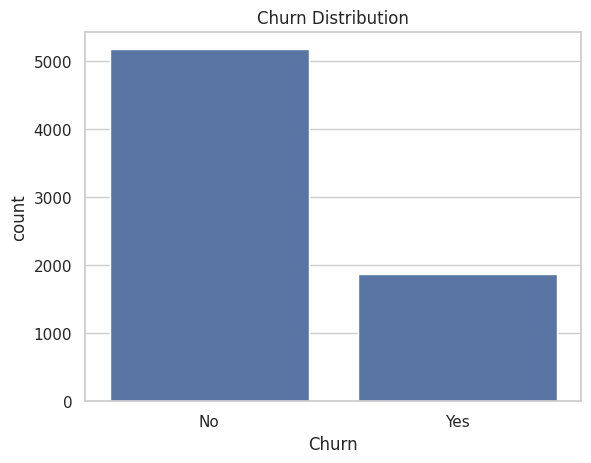

In [9]:
print("=== Churn Balance ===")
print(df['Churn'].value_counts())
print("\nPercent:")
print(df['Churn'].value_counts(normalize=True) * 100)

sns.countplot(x='Churn', data=df)
plt.title('Churn Distribution')
plt.show()

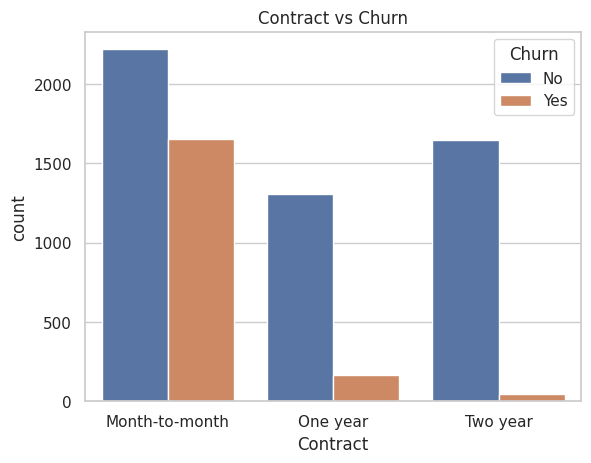

Churn rate by Contract:
Churn                  No        Yes
Contract                            
Month-to-month  57.290323  42.709677
One year        88.730482  11.269518
Two year        97.168142   2.831858


In [10]:
# 1. Contract vs Churn
sns.countplot(x='Contract', hue='Churn', data=df)
plt.title('Contract vs Churn')
plt.show()

print("Churn rate by Contract:")
print(df.groupby('Contract')['Churn'].value_counts(normalize=True).unstack() * 100)

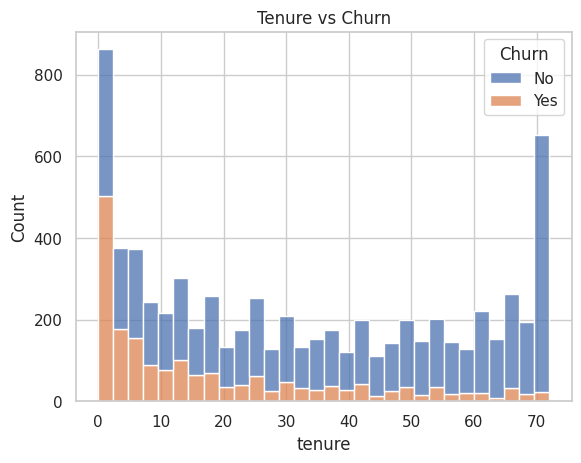

Average tenure by Churn:
Churn
No     37.569965
Yes    17.979133
Name: tenure, dtype: float64


In [11]:
# 2. Tenure vs Churn
sns.histplot(data=df, x='tenure', hue='Churn', multiple='stack', bins=30)
plt.title('Tenure vs Churn')
plt.show()

print("Average tenure by Churn:")
print(df.groupby('Churn')['tenure'].mean())

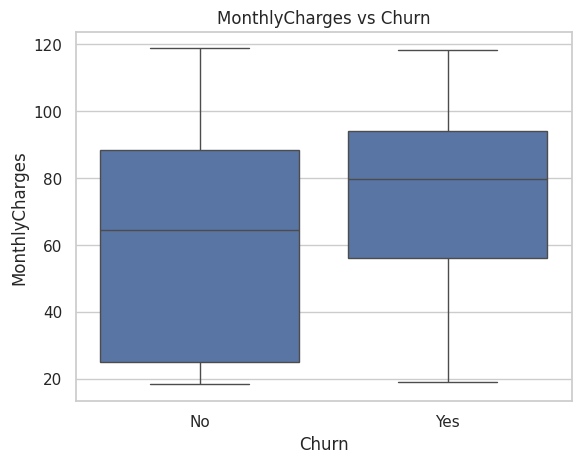

Average MonthlyCharges by Churn:
Churn
No     61.265124
Yes    74.441332
Name: MonthlyCharges, dtype: float64


In [12]:
# 3. MonthlyCharges vs Churn
sns.boxplot(x='Churn', y='MonthlyCharges', data=df)
plt.title('MonthlyCharges vs Churn')
plt.show()

print("Average MonthlyCharges by Churn:")
print(df.groupby('Churn')['MonthlyCharges'].mean())

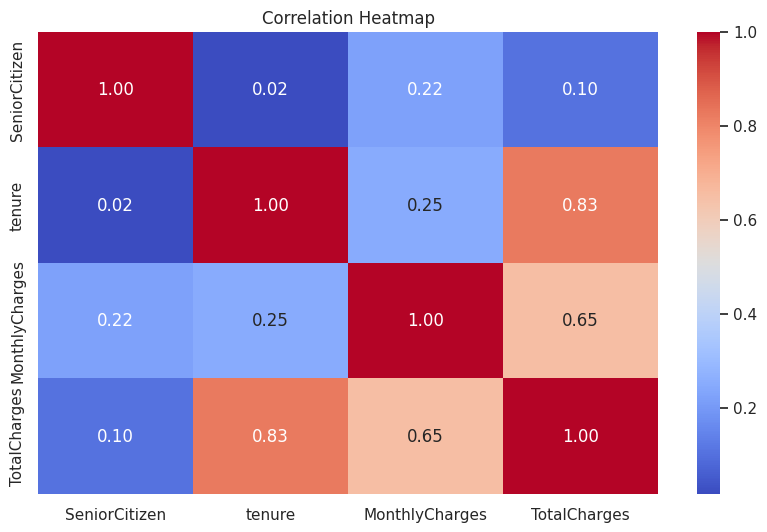

In [13]:
plt.figure(figsize=(10, 6))
numeric_df = df.select_dtypes(include=[np.number])
sns.heatmap(numeric_df.corr(), annot=True, cmap='coolwarm', fmt='.2f')
plt.title('Correlation Heatmap')
plt.show()

In [14]:
X = df.drop(['Churn', 'customerID'], axis=1)
y = df['Churn']

dummy = DummyClassifier(strategy='most_frequent')
dummy.fit(X, y)
y_pred = dummy.predict(X)

print("=== Baseline (Always Predict No Churn) ===")
print(classification_report(y, y_pred, zero_division=0))

print("Accuracy:", accuracy_score(y, y_pred))
print("Precision (Churn=Yes):", precision_score(y, y_pred, pos_label='Yes', zero_division=0))
print("Recall (Churn=Yes):", recall_score(y, y_pred, pos_label='Yes', zero_division=0))
print("F1 (Churn=Yes):", f1_score(y, y_pred, pos_label='Yes', zero_division=0))

=== Baseline (Always Predict No Churn) ===
              precision    recall  f1-score   support

          No       0.73      1.00      0.85      5174
         Yes       0.00      0.00      0.00      1869

    accuracy                           0.73      7043
   macro avg       0.37      0.50      0.42      7043
weighted avg       0.54      0.73      0.62      7043

Accuracy: 0.7346301292063041
Precision (Churn=Yes): 0.0
Recall (Churn=Yes): 0.0
F1 (Churn=Yes): 0.0


In [15]:
df.to_csv('clean_churn.csv', index=False)
print("CSV saved.")

CSV saved.


In [16]:
eda_report = """# EDA Findings
...your notes here...
"""
with open('EDA_FINDINGS.md', 'w') as f:
    f.write(eda_report)

In [17]:
baseline_report = """# Baseline Model

## Model
DummyClassifier(strategy='most_frequent') — always predicts "No Churn".

## Metrics
- Accuracy: 0.73
- Precision (Churn=Yes): 0.00
- Recall (Churn=Yes): 0.00
- F1 (Churn=Yes): 0.00

## Why Accuracy Is Misleading
The baseline gets 73% accuracy because 73% of customers stayed. But it catches 0% of churners. For the business, catching churners is the whole point. A model that never predicts churn is useless, even with 73% accuracy.

## Implication
Any real model must beat this on recall and F1 for the churn class. Do not judge future models on accuracy alone.
"""
with open('BASELINE.md', 'w') as f:
    f.write(baseline_report)
print("BASELINE.md created")

BASELINE.md created
